## 第6章「消費者の異質性を捉える」— サポートページ共通セットアップ

サポートページ全体で使用するパスの設定、DataFrame 表示スタイルの適用、および `matplotlib_fontja` のインポートを行う。

グラフで使用するグレースケールの色も定義する。


In [1]:
import sys
from pathlib import Path

import matplotlib_fontja  # noqa: F401
import pandas as pd
from IPython.display import display

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path))
        break
    if (path / "src" / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path / "src"))
        break

from common.notebook_style import apply_dataframe_style

apply_dataframe_style()

MONO_BLACK = "0.00"
MONO_DARK = "0.25"
MONO_MID = "0.50"
MONO_LIGHT = "0.75"

# 第6章 消費者の異質性を捉える

完全プール型ロジスティック回帰と階層ベイズモデルを比較し、消費者ごとの価格係数を全体の情報を一部共有する「部分プール」で推定します。価格係数は、観測データにおいてほかの条件をそろえたときの関連を表し、値下げによって生じた効果を直接表すものではありません。


## 第6章、第3節、第1項のコード

### 入力データの形式とサンプルデータの生成

1行を1回の購入機会とし、`occasion_id`、`customer_id`、円単位の`price_yen`、変換後の価格`price_scaled`、0/1の`purchased`を持たせます。ここでは $\mathrm{price\_scaled}=(\mathrm{price\_yen}-200)/50$ と定義するため、価格係数は価格が50円上がったときのロジット（対数オッズ）の変化を表します。


In [3]:
import numpy as np
import polars as pl

rng = np.random.default_rng(42)

N_customers = 100
N_obs_per = rng.integers(3, 30, size=N_customers)
customer_labels_true = np.array([f"C{i + 1:03d}" for i in range(N_customers)])

# シミュレーションにだけ存在する、母集団分布を決める真のパラメータ
mu_true = -0.8
sigma_true = 0.3
beta_price_true = rng.normal(mu_true, sigma_true, size=N_customers)
beta_0_true = rng.normal(0.0, 0.5, size=N_customers)

records = []
occasion_no = 1
for i in range(N_customers):
    n = N_obs_per[i]
    prices_yen = rng.uniform(100, 300, size=n)
    prices_scaled = (prices_yen - 200) / 50
    logit_p = beta_0_true[i] + beta_price_true[i] * prices_scaled
    prob = 1 / (1 + np.exp(-logit_p))
    purchased = rng.binomial(1, prob)
    for t in range(n):
        records.append(
            {
                "occasion_id": f"O{occasion_no:05d}",
                "customer_id": customer_labels_true[i],
                "price_yen": round(float(prices_yen[t]), 2),
                "price_scaled": round(float(prices_scaled[t]), 4),
                "purchased": int(purchased[t]),
            }
        )
        occasion_no += 1

df = pl.DataFrame(records)
df_head = df.head(5)
print(df.shape)
df_head

(1675, 5)


occasion_id,customer_id,price_yen,price_scaled,purchased
str,str,f64,f64,i64
"""O00001""","""C001""",121.06,-1.5789,1
"""O00002""","""C001""",113.31,-1.7338,1
"""O00003""","""C001""",218.89,0.3777,0
"""O00004""","""C001""",129.23,-1.4153,1
"""O00005""","""C001""",264.93,1.2987,0


### 消費者IDを配列内の番号へ変換

実務のIDは文字列や欠番を含むため、そのまま配列内の番号には使えません。`np.unique(..., return_inverse=True)`で、元のIDを保持したまま0始まりの連続整数へ変換します。


In [5]:
customer_labels, customer_idx = np.unique(
    df["customer_id"].to_numpy(), return_inverse=True
)
customer_idx = customer_idx.astype("int32")
prices_obs = df["price_scaled"].to_numpy()
purchased_obs = df["purchased"].to_numpy().astype("int8")

N_customers_obs = len(customer_labels)
print(f"消費者数: {N_customers_obs}, 観測数の合計: {len(df)}")
print(
    "IDと配列内の番号の対応（先頭3件）:",
    dict(zip(customer_labels[:3], range(3))),
)

消費者数: 100, 観測数の合計: 1675
IDと配列内の番号の対応（先頭3件）: {'C001': 0, 'C002': 1, 'C003': 2}


## 第6章、第3節、第2項のコード

### モデルの仮定

本章では、消費者ごとの切片と価格係数がそれぞれ正規分布に従い、両者の相関はないと仮定します。購入を説明する変数は価格だけです。実務では販促、店舗、季節、商品属性などを追加し、必要に応じて切片と傾きの相関もモデル化します。

数式の $\mathcal{N}(\mu, \sigma^2)$ では第2引数を分散として表記しています。一方、PyMCの `pm.Normal` に渡す `sigma` は標準偏差です。そのため、コードでは `sigma_beta`（または `sigma_beta0`）をそのまま使い、二乗しません。

実装では、平均0・標準偏差1の正規分布に従う変数 $z_i$ を使い、価格係数を次のように表します。

$$
\beta_{\mathrm{price},i}=\mu_\beta+\sigma_\beta z_i
$$

この書き方を「非中心化パラメータ化」と呼び、元の正規分布を変えずに、計算をしやすくするために使います。この式でも、標準偏差 $\sigma_\beta$ をそのまま掛け、二乗しません。

### 完全プール型ロジスティック回帰


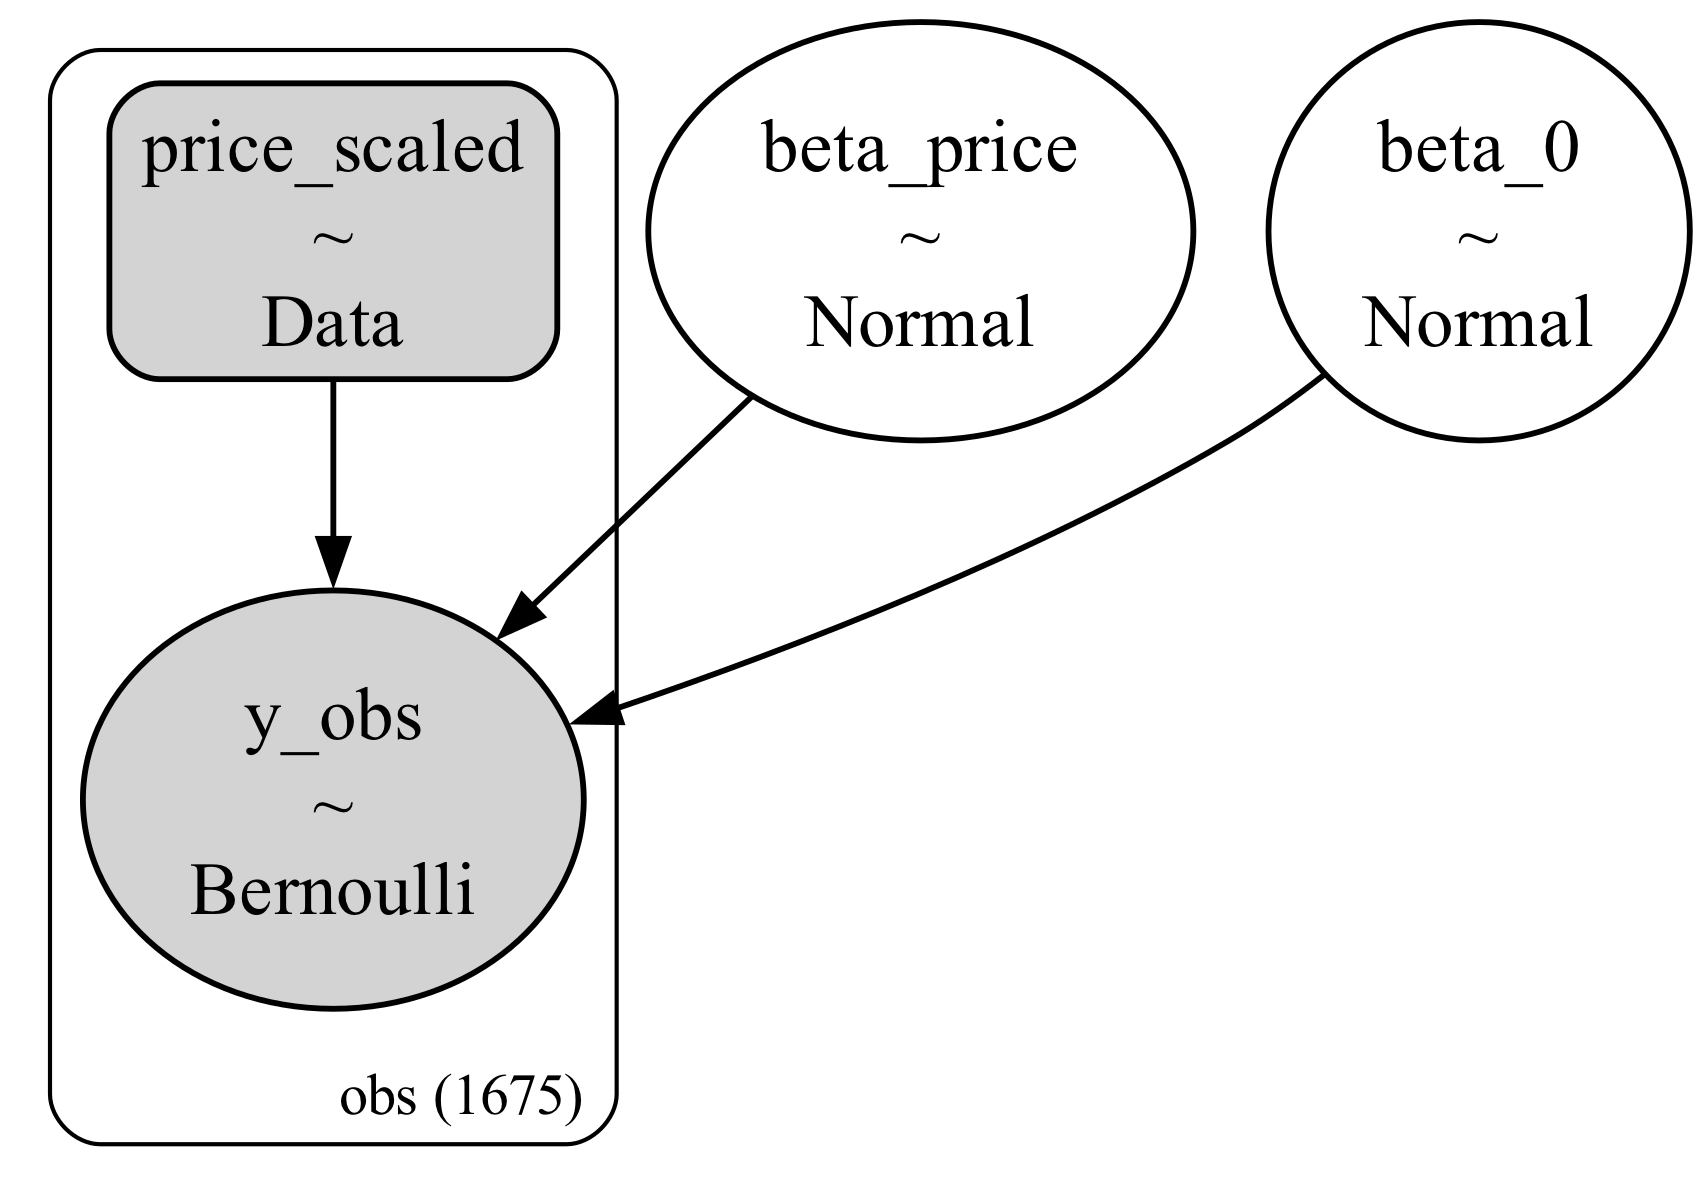

In [6]:
import pymc as pm

obs_coords = np.arange(len(df))

with pm.Model(coords={"obs": obs_coords}) as pooled_model:
    price_data_pooled = pm.Data("price_scaled", prices_obs, dims="obs")
    beta_0 = pm.Normal("beta_0", mu=0, sigma=1)
    beta_price = pm.Normal("beta_price", mu=0, sigma=1)
    logit_p_pooled = beta_0 + beta_price * price_data_pooled
    pm.Bernoulli(
        "y_obs", logit_p=logit_p_pooled, observed=purchased_obs, dims="obs"
    )

graph_pooled = pm.model_to_graphviz(pooled_model)
graph_pooled.graph_attr.update(dpi="300", bgcolor="white")
graph_pooled.node_attr.update(fontsize="18", penwidth="1.4")
graph_pooled.edge_attr.update(color="black", penwidth="1.4")
display(graph_pooled)

### 階層ベイズモデル

計算を安定させるための書き方を使い、母集団分布から消費者ごとの切片と価格係数を作ります。`customer_idx`により、データの各行について、対応する消費者の係数を参照します。


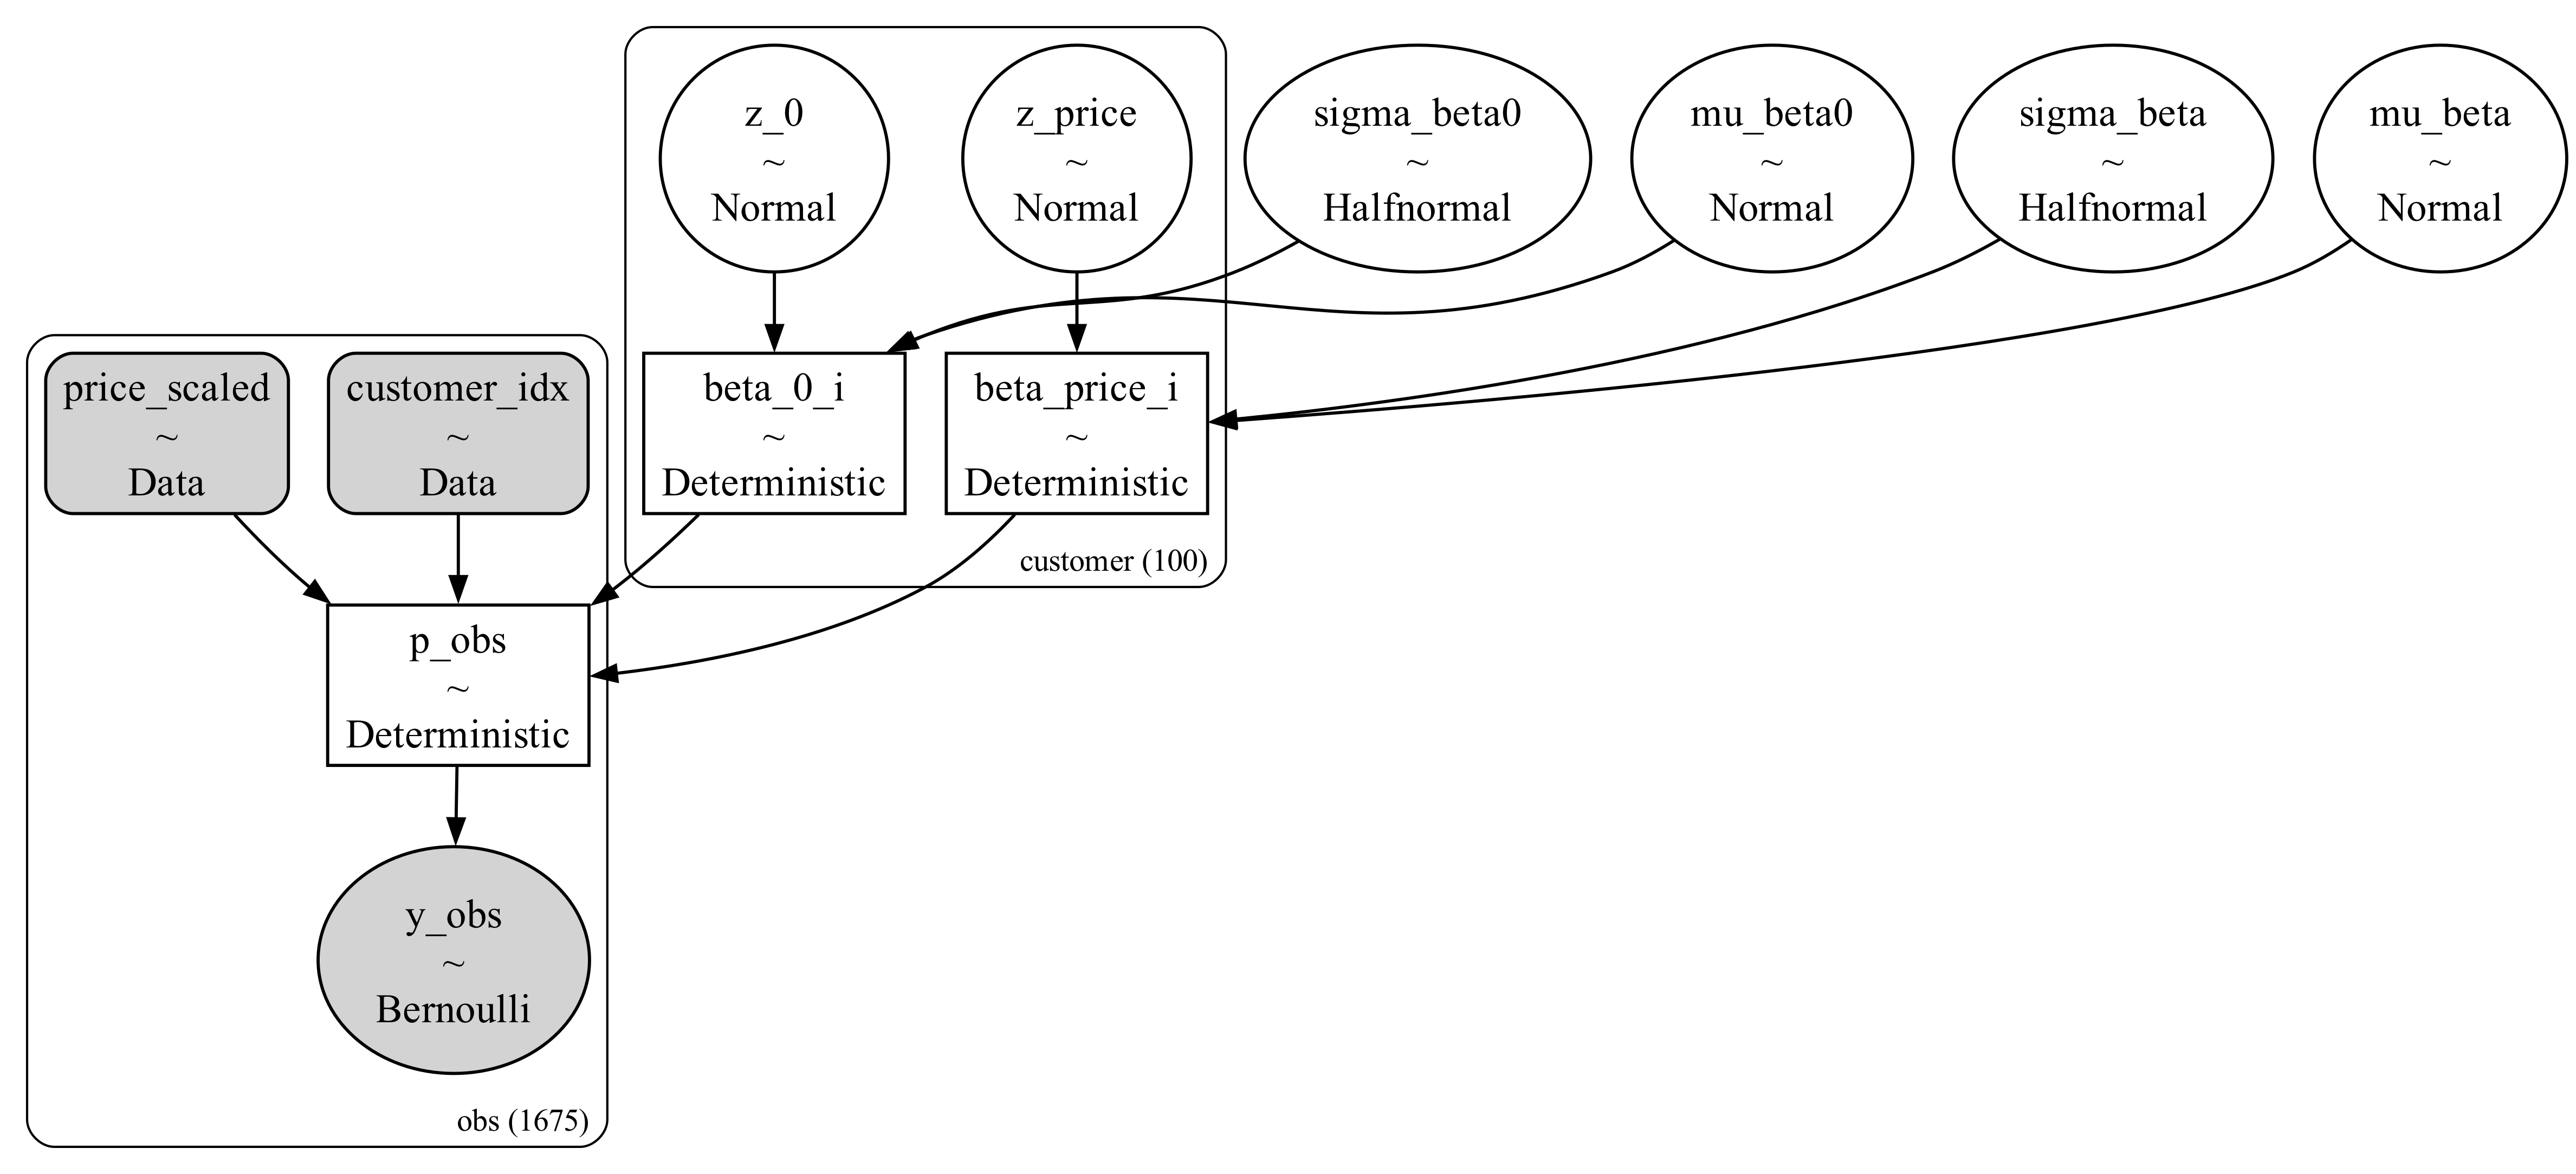

In [7]:
model_coords = {
    "customer": customer_labels.tolist(),
    "obs": obs_coords,
}

with pm.Model(coords=model_coords) as hierarchical_model:
    customer_idx_data = pm.Data("customer_idx", customer_idx, dims="obs")
    price_data = pm.Data("price_scaled", prices_obs, dims="obs")

    # 第1層：母集団分布を決めるパラメータの事前分布
    mu_beta = pm.Normal("mu_beta", mu=0, sigma=1)
    sigma_beta = pm.HalfNormal("sigma_beta", sigma=1)
    mu_beta0 = pm.Normal("mu_beta0", mu=0, sigma=1)
    sigma_beta0 = pm.HalfNormal("sigma_beta0", sigma=1)

    # 第2層：消費者ごとのパラメータ（計算を安定させる書き方）
    z_price = pm.Normal("z_price", mu=0, sigma=1, dims="customer")
    z_0 = pm.Normal("z_0", mu=0, sigma=1, dims="customer")
    beta_price_i = pm.Deterministic(
        "beta_price_i", mu_beta + sigma_beta * z_price, dims="customer"
    )
    beta_0_i = pm.Deterministic(
        "beta_0_i", mu_beta0 + sigma_beta0 * z_0, dims="customer"
    )

    # 第3層：観測モデル
    logit_p = (
        beta_0_i[customer_idx_data]
        + beta_price_i[customer_idx_data] * price_data
    )
    p_obs = pm.Deterministic("p_obs", pm.math.sigmoid(logit_p), dims="obs")
    pm.Bernoulli("y_obs", p=p_obs, observed=purchased_obs, dims="obs")

graph_hierarchical = pm.model_to_graphviz(hierarchical_model)
graph_hierarchical.graph_attr.update(dpi="300", bgcolor="white")
graph_hierarchical.node_attr.update(fontsize="18", penwidth="1.4")
graph_hierarchical.edge_attr.update(color="black", penwidth="1.4")
display(graph_hierarchical)

### 事前予測による確認

データを見る前に、設定した事前分布がどのような購入確率を許すか確認します。曲線が0か1付近に過度に集中する場合は、価格の変換方法や事前分布を見直します。


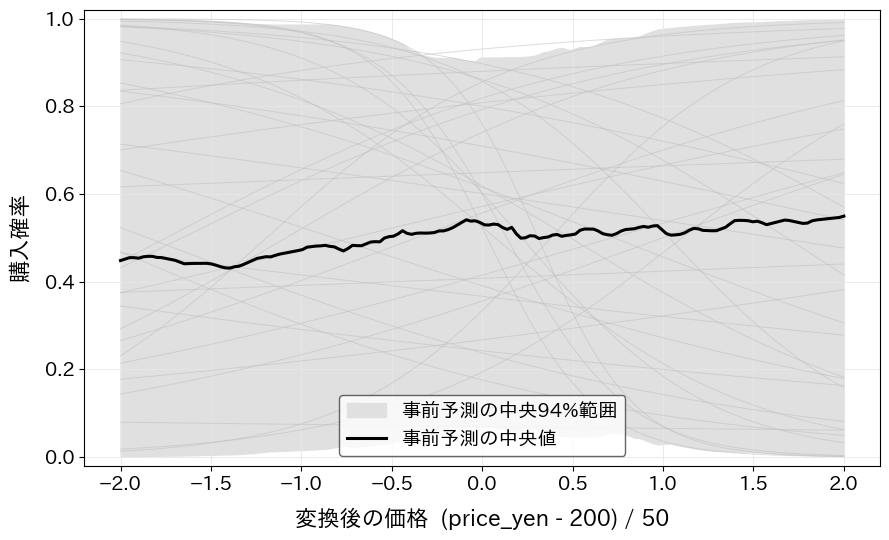

In [8]:
import matplotlib.pyplot as plt

prior_rng = np.random.default_rng(2026)
price_grid = np.linspace(-2, 2, 160)
n_prior_curves = 200
mu_beta_prior = prior_rng.normal(0, 1, n_prior_curves)
sigma_beta_prior = np.abs(prior_rng.normal(0, 1, n_prior_curves))
mu_beta0_prior = prior_rng.normal(0, 1, n_prior_curves)
sigma_beta0_prior = np.abs(prior_rng.normal(0, 1, n_prior_curves))
beta_prior = prior_rng.normal(mu_beta_prior, sigma_beta_prior)
beta0_prior = prior_rng.normal(mu_beta0_prior, sigma_beta0_prior)
prior_prob = 1 / (
    1 + np.exp(-(beta0_prior[:, None] + beta_prior[:, None] * price_grid))
)
prior_hdi = np.quantile(prior_prob, [0.03, 0.97], axis=0)

fig, ax = plt.subplots(figsize=(9, 5.5))
for curve in prior_prob[:35]:
    ax.plot(price_grid, curve, color=MONO_LIGHT, linewidth=0.7, alpha=0.55)
ax.fill_between(
    price_grid,
    prior_hdi[0],
    prior_hdi[1],
    color="0.88",
    label="事前予測の中央94%範囲",
)
ax.plot(
    price_grid,
    np.median(prior_prob, axis=0),
    color=MONO_BLACK,
    linewidth=2.2,
    label="事前予測の中央値",
)
ax.set_xlabel(
    "変換後の価格  (price_yen - 200) / 50",
    fontsize=16,
    labelpad=10,
)
ax.set_ylabel("購入確率", fontsize=16, labelpad=10)
ax.set_ylim(-0.02, 1.02)
ax.tick_params(axis="both", labelsize=14)
ax.grid(True, color="0.9", linewidth=0.6)
ax.legend(
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
    fontsize=14,
)
fig.tight_layout()
plt.show()

## 第6章、第3節、第3項のコード

### MCMCによるサンプリング

以下ではNUTSを4チェーン実行します。計算後は、$\hat R$だけでなく、有効サンプルサイズ、発散、BFMI、サンプル列の推移図を併せて確認します。


In [9]:
with hierarchical_model:
    trace = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=42,
        return_inferencedata=True,
    )

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_beta, sigma_beta, mu_beta0, sigma_beta0, z_price, z_0]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 9 seconds.


### 学習に使ったデータの事後予測を確認する

まず、異なる消費者から1行ずつ選び、学習に使ったデータに対する購入確率とモデルから生成した購入結果を確認します。これは未知の将来データに対する予測の正確さを測るものではなく、モデルが観測データを再現できるかを確認するものです。


In [10]:
import arviz as az

with hierarchical_model:
    posterior_predictive = pm.sample_posterior_predictive(
        trace,
        var_names=["y_obs"],
        random_seed=42,
        return_inferencedata=True,
    )

p_obs_samples = (
    trace.posterior["p_obs"]
    .stack(sample=("chain", "draw"))
    .transpose("sample", "obs")
    .values
)
y_pred_samples = (
    posterior_predictive.posterior_predictive["y_obs"]
    .stack(sample=("chain", "draw"))
    .transpose("sample", "obs")
    .values
)

selected_customers = [0, 24, 49, 74, 99]
summary_idx = np.array(
    [np.flatnonzero(customer_idx == i)[0] for i in selected_customers]
)
p_hdi = np.vstack([az.hdi(p_obs_samples[:, j], prob=0.94) for j in summary_idx])
posterior_pred_summary = pl.DataFrame(
    {
        "occasion_id": df["occasion_id"].to_numpy()[summary_idx],
        "customer_id": customer_labels[customer_idx[summary_idx]],
        "price_scaled": prices_obs[summary_idx],
        "y_actual": purchased_obs[summary_idx],
        "p_mean": p_obs_samples[:, summary_idx].mean(axis=0),
        "p_hdi94_low": p_hdi[:, 0],
        "p_hdi94_high": p_hdi[:, 1],
        "y_rep_rate": y_pred_samples[:, summary_idx].mean(axis=0),
    }
).with_columns(
    pl.col(
        ["price_scaled", "p_mean", "p_hdi94_low", "p_hdi94_high", "y_rep_rate"]
    ).round(3)
)
print(posterior_pred_summary.to_pandas().to_string(index=False))

Sampling: [y_obs]


occasion_id customer_id  price_scaled  y_actual  p_mean  p_hdi94_low  p_hdi94_high  y_rep_rate
     O00001        C001        -1.579         1   0.782        0.615         0.936       0.783
     O00405        C025         1.904         0   0.180        0.058         0.297       0.183
     O00834        C050        -0.561         0   0.552        0.401         0.704       0.553
     O01233        C075         1.230         0   0.183        0.068         0.308       0.184
     O01670        C100         1.991         0   0.210        0.054         0.382       0.224


### 事後予測による確認

価格帯ごとの実測購入率と、事後予測で生成した購入率を比較します。実測値の黒丸が事後予測の94% HDIから大きく外れる価格帯では、価格だけのモデルでは説明できない特徴が残っている可能性があります。


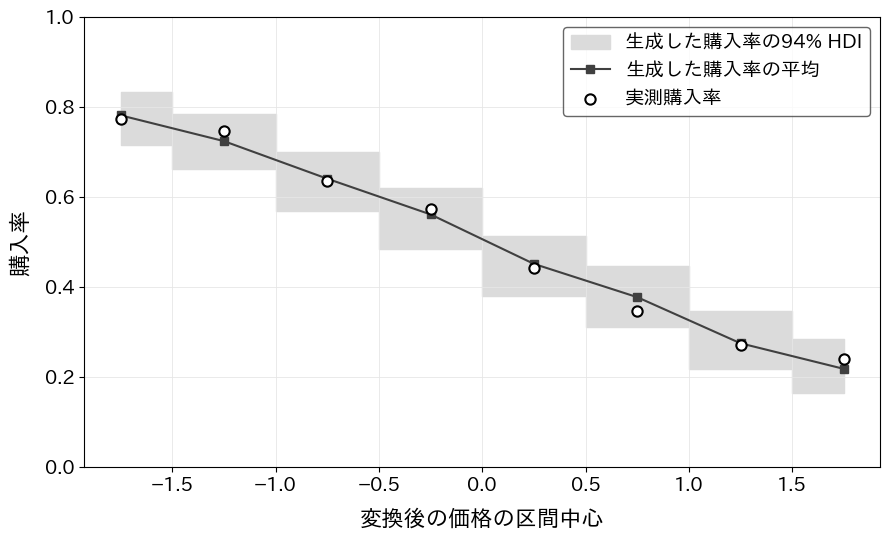

In [11]:
price_bin_edges = np.linspace(-2, 2, 9)
price_bin = np.digitize(prices_obs, price_bin_edges[1:-1])
bin_centers = (price_bin_edges[:-1] + price_bin_edges[1:]) / 2
obs_rate = np.array(
    [purchased_obs[price_bin == b].mean() for b in range(len(bin_centers))]
)
rep_rate = np.column_stack(
    [
        y_pred_samples[:, price_bin == b].mean(axis=1)
        for b in range(len(bin_centers))
    ]
)
rep_hdi = np.vstack(
    [az.hdi(rep_rate[:, b], prob=0.94) for b in range(rep_rate.shape[1])]
)
rep_mean = rep_rate.mean(axis=0)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.fill_between(
    bin_centers,
    rep_hdi[:, 0],
    rep_hdi[:, 1],
    color="0.86",
    step="mid",
    label="生成した購入率の94% HDI",
)
ax.plot(
    bin_centers,
    rep_mean,
    color=MONO_DARK,
    marker="s",
    label="生成した購入率の平均",
)
ax.scatter(
    bin_centers,
    obs_rate,
    s=55,
    facecolor="white",
    edgecolor=MONO_BLACK,
    linewidth=1.5,
    label="実測購入率",
    zorder=3,
)
ax.set_xlabel("変換後の価格の区間中心", fontsize=16, labelpad=10)
ax.set_ylabel("購入率", fontsize=16, labelpad=10)
ax.set_ylim(0, 1)
ax.tick_params(axis="both", labelsize=14)
ax.grid(True, color="0.9", linewidth=0.6)
ax.legend(
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
    fontsize=14,
)
fig.tight_layout()
plt.show()

### 計算結果が安定しているかの確認：$\hat R$、ESS、発散、BFMI

モデル内でサンプリングするすべてのパラメータを確認します。$\hat R\leq1.01$だけでは、計算が安定しているとは判断できません。ESS、発散数、BFMI、次のサンプル列の推移図も併せて確認します。


In [12]:
diagnostic_vars = [
    "mu_beta",
    "sigma_beta",
    "mu_beta0",
    "sigma_beta0",
    "z_price",
    "z_0",
]
diagnostics = az.summary(trace, var_names=diagnostic_vars, kind="diagnostics")
max_rhat = pd.to_numeric(diagnostics["r_hat"], errors="coerce").max()
min_ess_bulk = pd.to_numeric(diagnostics["ess_bulk"], errors="coerce").min()
min_ess_tail = pd.to_numeric(diagnostics["ess_tail"], errors="coerce").min()
divergences = int(trace.sample_stats["diverging"].sum().item())
energy = trace.sample_stats["energy"].values
bfmi = np.mean(np.diff(energy, axis=1) ** 2, axis=1) / np.var(energy, axis=1)

print(f"最大 r_hat: {max_rhat:.3f}")
print(f"最小 ESS (bulk / tail): {min_ess_bulk:.0f} / {min_ess_tail:.0f}")
print(f"発散数: {divergences}")
print("BFMI（チェーン別）:", np.round(bfmi, 3))

for name in ["mu_beta", "sigma_beta", "mu_beta0", "sigma_beta0"]:
    values = trace.posterior[name].values.reshape(-1)
    low, high = az.hdi(values, prob=0.94)
    print(
        f"{name:12s} mean={values.mean(): .3f}, 94% HDI=[{low: .3f}, {high: .3f}]"
    )

最大 r_hat: 1.003
最小 ESS (bulk / tail): 1636 / 1784
発散数: 0
BFMI（チェーン別）: [0.721 0.753 0.692 0.667]
mu_beta      mean=-0.794, 94% HDI=[-0.907, -0.688]
sigma_beta   mean= 0.188, 94% HDI=[ 0.001,  0.337]
mu_beta0     mean= 0.016, 94% HDI=[-0.119,  0.166]
sigma_beta0  mean= 0.493, 94% HDI=[ 0.327,  0.672]


### 計算結果が安定しているかの確認：サンプル列の推移図

紙面では母集団の価格係数と代表3人の価格係数を表示します。これは抜粋表示なので、表示していない変数も直前の数値診断の対象に含めています。


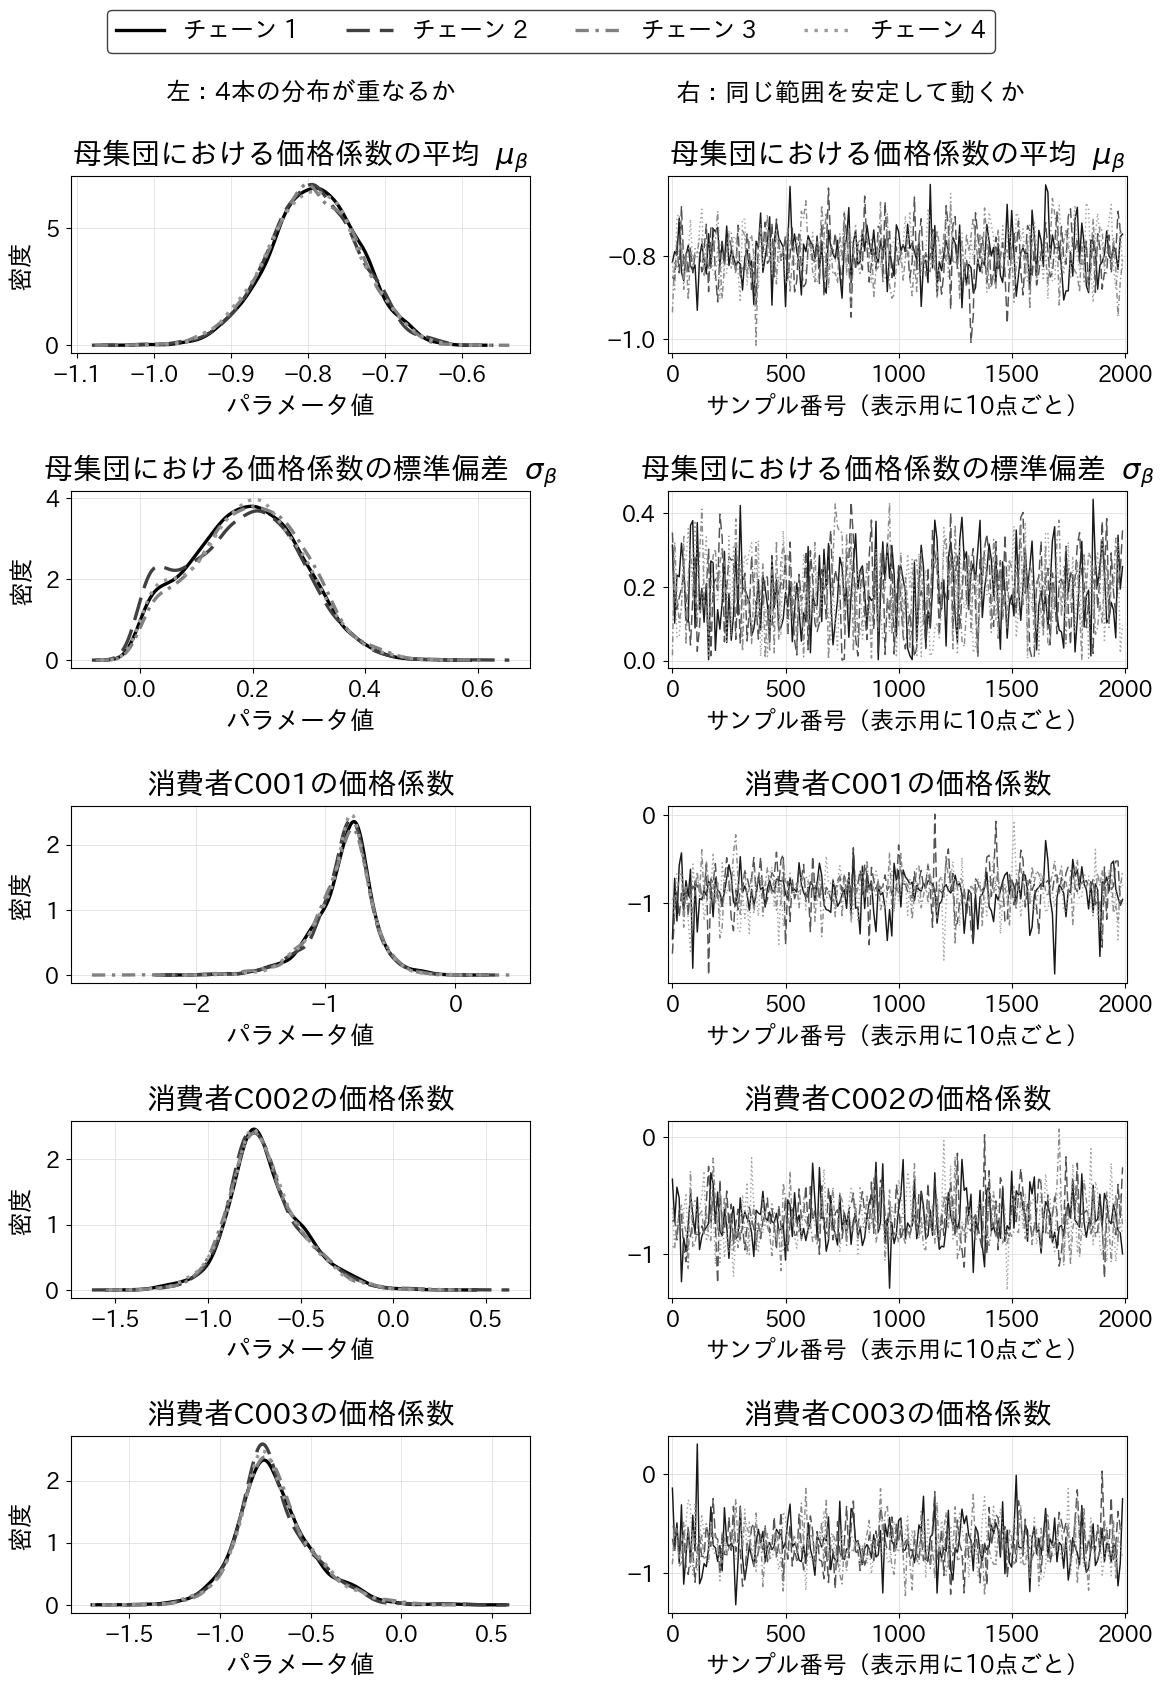

In [13]:
from scipy import stats

var_specs = [
    ("mu_beta", None, r"母集団における価格係数の平均  $\mu_{\beta}$"),
    ("sigma_beta", None, r"母集団における価格係数の標準偏差  $\sigma_{\beta}$"),
    ("beta_price_i", 0, r"消費者C001の価格係数"),
    ("beta_price_i", 1, r"消費者C002の価格係数"),
    ("beta_price_i", 2, r"消費者C003の価格係数"),
]

n_vars = len(var_specs)
fig, axes = plt.subplots(n_vars, 2, figsize=(12, 17))
chain_styles = [
    {"color": MONO_BLACK, "linestyle": "-"},
    {"color": MONO_DARK, "linestyle": (0, (7, 3))},
    {"color": MONO_MID, "linestyle": (0, (4, 2, 1, 2))},
    {"color": "0.60", "linestyle": (0, (1, 2))},
]
display_step = 10
legend_handles = []

for row, (var_name, idx, label) in enumerate(var_specs):
    ax_kde, ax_trace = axes[row]
    if idx is not None:
        samples = trace.posterior[var_name][:, :, idx].values
    else:
        samples = trace.posterior[var_name].values

    for c in range(samples.shape[0]):
        s = samples[c]
        style = chain_styles[c % len(chain_styles)]
        margin = (s.max() - s.min()) * 0.15
        x = np.linspace(s.min() - margin, s.max() + margin, 300)
        kde = stats.gaussian_kde(s)
        (line,) = ax_kde.plot(
            x,
            kde(x),
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=2.4,
            label=f"チェーン {c + 1}",
        )
        if row == 0:
            legend_handles.append(line)
    ax_kde.set_title(label, fontsize=21, pad=9)
    ax_kde.set_xlabel("パラメータ値", fontsize=18, labelpad=6)
    ax_kde.set_ylabel("密度", fontsize=18, labelpad=8)
    ax_kde.tick_params(labelsize=16, pad=5)
    ax_kde.grid(True, color="0.88", linewidth=0.6)

    for c in range(samples.shape[0]):
        style = chain_styles[c % len(chain_styles)]
        draw_numbers = np.arange(samples.shape[1])[::display_step]
        ax_trace.plot(
            draw_numbers,
            samples[c, ::display_step],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.05,
            alpha=0.9,
        )
    ax_trace.set_title(label, fontsize=21, pad=9)
    ax_trace.set_xlabel(
        "サンプル番号（表示用に10点ごと）", fontsize=17, labelpad=6
    )
    ax_trace.tick_params(labelsize=16, pad=5)
    ax_trace.grid(True, color="0.88", linewidth=0.6)
    ax_trace.margins(x=0.01)

fig.text(
    0.30,
    0.935,
    "左：4本の分布が重なるか",
    ha="center",
    fontsize=18,
    weight="bold",
)
fig.text(
    0.75,
    0.935,
    "右：同じ範囲を安定して動くか",
    ha="center",
    fontsize=18,
    weight="bold",
)
fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=4,
    bbox_to_anchor=(0.5, 0.995),
    fontsize=17,
    frameon=True,
    facecolor="white",
    edgecolor=MONO_DARK,
    framealpha=1.0,
)
fig.subplots_adjust(
    left=0.10, right=0.98, bottom=0.045, top=0.89, hspace=0.78, wspace=0.30
)
plt.show()

### 消費者ごとの推定値、値の幅、縮小の確認

各消費者について価格係数の事後平均と94% HDIを出力します。シミュレーションでは、データを作るときに設定した値（以下、真値）も分かるため推定値と比較でき、観測数が少ないほど係数としてあり得る値の幅が広がりやすいことも確認できます。実務の対象者選定では、点推定値だけでなくHDIが示す値の幅も判断に使います。


customer_id  n_obs  beta_mean  hdi94_low  hdi94_high  strong_negative
       C017     16     -0.926     -1.413      -0.573             True
       C062     23     -0.909     -1.339      -0.532             True
       C015     22     -0.902     -1.343      -0.552             True
       C038     25     -0.898     -1.328      -0.542             True
       C059     23     -0.897     -1.328      -0.542             True
       C013     22     -0.893     -1.328      -0.559             True
       C028     25     -0.891     -1.324      -0.543             True
       C024     28     -0.888     -1.292      -0.533             True


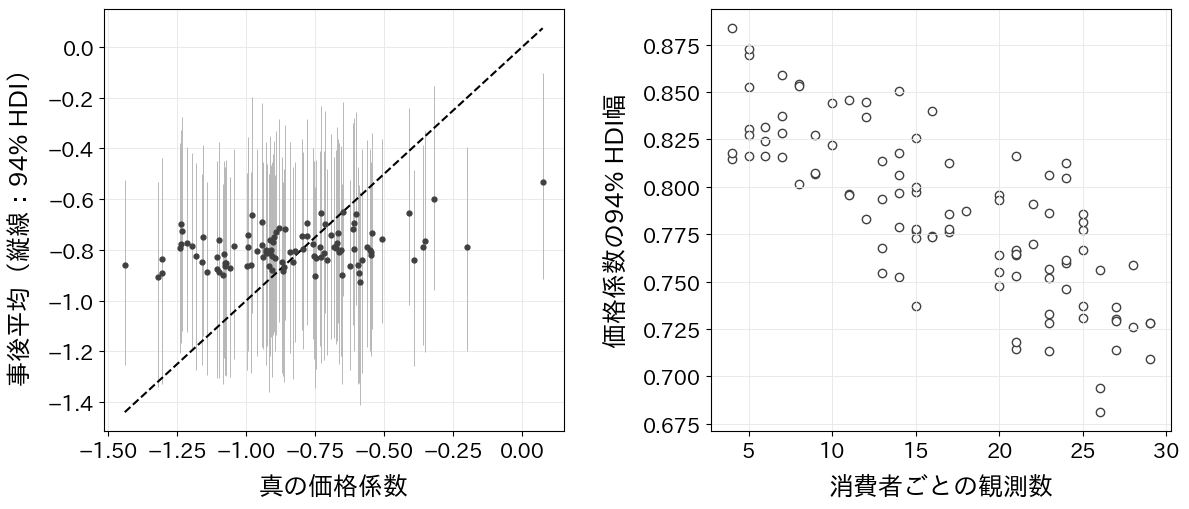

In [14]:
beta_samples = (
    trace.posterior["beta_price_i"]
    .stack(sample=("chain", "draw"))
    .transpose("sample", "customer")
    .values
)
beta_mean = beta_samples.mean(axis=0)
beta_hdi = np.vstack(
    [az.hdi(beta_samples[:, i], prob=0.94) for i in range(N_customers_obs)]
)
n_obs = np.bincount(customer_idx, minlength=N_customers_obs)
hdi_width = beta_hdi[:, 1] - beta_hdi[:, 0]

# 例：94% HDIの上限も-0.5未満なら「強い負の関連が比較的明確」と判定
strong_negative = beta_hdi[:, 1] < -0.5
customer_summary = pl.DataFrame(
    {
        "customer_id": customer_labels,
        "n_obs": n_obs,
        "beta_mean": beta_mean,
        "hdi94_low": beta_hdi[:, 0],
        "hdi94_high": beta_hdi[:, 1],
        "strong_negative": strong_negative,
    }
).with_columns(pl.col(["beta_mean", "hdi94_low", "hdi94_high"]).round(3))
customer_summary_top = customer_summary.sort("beta_mean").head(8)
print(customer_summary_top.to_pandas().to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
axes[0].errorbar(
    beta_price_true,
    beta_mean,
    yerr=[beta_mean - beta_hdi[:, 0], beta_hdi[:, 1] - beta_mean],
    fmt="o",
    markersize=3.5,
    color=MONO_DARK,
    ecolor="0.72",
    elinewidth=0.7,
    capsize=0,
)
plot_min = min(beta_price_true.min(), beta_hdi[:, 0].min())
plot_max = max(beta_price_true.max(), beta_hdi[:, 1].max())
axes[0].plot(
    [plot_min, plot_max], [plot_min, plot_max], color=MONO_BLACK, linestyle="--"
)
axes[0].set_xlabel("真の価格係数", fontsize=18, labelpad=10)
axes[0].set_ylabel("事後平均（縦線：94% HDI）", fontsize=18, labelpad=10)

axes[1].scatter(n_obs, hdi_width, facecolor="white", edgecolor=MONO_DARK)
axes[1].set_xlabel("消費者ごとの観測数", fontsize=18, labelpad=10)
axes[1].set_ylabel("価格係数の94% HDI幅", fontsize=18, labelpad=10)
for ax in axes:
    ax.tick_params(axis="both", labelsize=15)
    ax.grid(True, color="0.9", linewidth=0.6)
fig.tight_layout(w_pad=3.0)
plt.show()

### 完全プール型モデルと母集団の推定値の比較

最後に、完全プール型モデルの共通の価格係数と、階層ベイズモデルの母集団における価格係数の平均を並べます。これは推定値の比較であり、予測の正確さに基づく正式なモデル比較ではありません。


In [16]:
with pooled_model:
    trace_pooled = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=42,
        return_inferencedata=True,
    )

pooled_samples = trace_pooled.posterior["beta_price"].values.reshape(-1)
hierarchical_mean_samples = trace.posterior["mu_beta"].values.reshape(-1)
comparison_rows = []
for model_name, samples in [
    ("完全プール型モデル：共通の価格係数", pooled_samples),
    (
        "階層ベイズモデル：母集団における価格係数の平均",
        hierarchical_mean_samples,
    ),
]:
    low, high = az.hdi(samples, prob=0.94)
    comparison_rows.append(
        {
            "estimate": model_name,
            "mean": samples.mean(),
            "hdi94_low": low,
            "hdi94_high": high,
        }
    )

estimate_comparison = pd.DataFrame(comparison_rows).round(3)
print(estimate_comparison.to_string(index=False))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [beta_0, beta_price]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.


               estimate   mean  hdi94_low  hdi94_high
      完全プール型モデル：共通の価格係数 -0.749     -0.840      -0.656
階層ベイズモデル：母集団における価格係数の平均 -0.794     -0.907      -0.688
